# CelebA Female Arm, DR Support Capped at 4096: n = 16384

Doubly robust counterfactual face sampling on the CelebA attribute-rebalancing design (Dance
et al., 2026, Section 5.4; see `dgp_analysis/CelebA.ipynb` for the verified construction). The
interventional law $P(Y(0))$ is represented by its cross-fitted doubly robust mean embedding
over frozen SD-VAE latents of the logged faces, and samples are generated by minimising the
weighted Riesz energy distance with AdamW over the particle latents. The female arm
($a^\* = 0$) must move its blond fraction downward toward the balanced interventional mixture.

**This notebook is one half of a matched pair at $n = 16384$.** The two halves differ in exactly
one thing, the support on which the DR weights and the target embedding are built:

| notebook | DR support | solver |
| --- | --- | --- |
| `CelebA_Female_DR_FullSupport_n16384.ipynb` | every logged row | Nystrom, 1024 landmarks |
| `CelebA_Female_DR_Subset4096_n16384.ipynb` | at most 4096 rows | exact |

At $n = 16384$ the cap binds and the capped run sees a quarter of the logged rows. This is the
pre-2026-09 configuration (`--solver exact --n_dr 4096`) that the current code replaced.

Seed, particle count, flow schedule, iteration count, references and every metric are held
fixed across the pair, so any difference in the tables below is attributable to the support.


In [1]:
import sys
import json
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

sys.path.append("../../src")
torch.set_default_dtype(torch.float32)

from data_utils import binary_stats, load_celeba_paper
from data_utils.celeba import to_image_range
from autoencoder_utils import decode_latents, encode_images, load_sd_vae
from causality_utils import (cpme_dr_weights_crossfit,
                             cpme_dr_weights_crossfit_nystrom,
                             make_crossfit_fold_ids, select_regularization)
from dens_ratio_utils import crossfit_propensity
from mmd_flow_utils import adamw_riesz_flow, squared_mmd
from metric_utils import CleanFIDScorer, LegacyFIDScorer, sliced_wasserstein
from kernel_utils import RBF

SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)


device: cuda


## 1. Data

Controlled observational sample ($n = 16384$ at $256 \\times 256$; $A = \\mathrm{Male}$,
$X = \\mathrm{BlondHair}$, prescribed $P(X{=}1) = 0.3$, $P(A{=}1|X{=}0) = 0.6$,
$P(A{=}1|X{=}1) = 0.1$) plus 2000 held-out balanced reference images per interventional
arm (the evaluation construction of Dance et al., 2026, App. B.3), drawn disjointly from the
same pool. The observed female arm has blond fraction $\\approx 0.49$; the interventional
mixture is $0.30$.


In [2]:
TARGET_A = 0
N_OBS = 16384
CACHE = "../../data/celeba_dgp/celeba_paper_256_n16384_nref2000_seed0.pt"
CELEBA_ROOT = "/nfs/ghome/live/danceh/data/celeba"   # machine-local; used only to (re)generate

data = load_celeba_paper(CACHE, root=CELEBA_ROOT, seed=0, image_size=256,
                         n_obs=N_OBS, n_ref=2000, verbose=False)
A = data["A"].view(-1).long()
X = data["X"].view(-1).long()
Y = data["Y"]
Y_ref = data[f"Y{TARGET_A}_ref"]
stats = binary_stats(A, X)
arm = A == TARGET_A
n = len(A)
print(f"n = {stats['n']}   cells (A,X) = { {k: v for k, v in sorted(stats['cells'].items())} }")
print(f"arm a={TARGET_A} size = {int(arm.sum())}   observed blond fraction "
      f"E[X|A={TARGET_A}] = {X[arm].float().mean():.3f}   (interventional marginal 0.300)")


n = 16384   cells (A,X) = {(0, 0): 4587, (0, 1): 4424, (1, 0): 6881, (1, 1): 492}
arm a=0 size = 9011   observed blond fraction E[X|A=0] = 0.491   (interventional marginal 0.300)


## 2. SD-VAE Latents

A frozen pretrained VAE (`stabilityai/sd-vae-ft-mse`) supplies the latent space: the encoder
maps each face to a flattened $4 \times 32 \times 32 = 4096$-dimensional code and the decoder
maps transported latents back to faces. Latents are standardised per coordinate so the
isotropic energy kernel treats all coordinates comparably.


In [3]:
vae = load_sd_vae(device)
Z = encode_images(vae, Y)
Z_ref = encode_images(vae, Y_ref)
latent_mean = Z.mean(dim=0, keepdim=True)
latent_std = Z.std(dim=0, keepdim=True).clamp_min(1e-3)
to_flow = lambda z: (z - latent_mean) / latent_std
from_flow = lambda p: p * latent_std + latent_mean
Z_std, Z_ref_std = to_flow(Z), to_flow(Z_ref)
print(f"latents: {tuple(Z.shape)}, standardised per coordinate")


/nfs/ghome/live/bbozkurt/.conda/envs/torchnn/lib/python3.12/site-packages/huggingface_hub/utils/_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


latents: (16384, 4096), standardised per coordinate


## 3. Cross-Fitted DR Weights --- Capped Support (Exact Solve on a 4096-Row Subsample)

This is the pre-2026-09 configuration, `--solver exact --n_dr 4096`. The DR support is a
random subsample of at most 4096 logged rows; the ridge system of each fold is then small
enough to solve exactly. Everything else in this notebook matches its full-support sibling.

The cap changes two things at once, and they are not separable: the weights are cross-fitted
on fewer rows, and the target embedding $\hat\chi(0) = \sum_i v_i\, k_Y(z_i, \cdot)$ is
carried by fewer atoms, so the flow has a coarser target to descend towards.


In [4]:
DR_SUPPORT = "subset"
N_DR_CAP = 4096
if N_DR_CAP < n:
    dr_index = torch.randperm(n, generator=torch.Generator().manual_seed(SEED + 5))[:N_DR_CAP]
    dr_index, _ = torch.sort(dr_index)
    print(f"DR support: {N_DR_CAP} of {n} logged rows (cap binds)")
else:
    dr_index = torch.arange(n)
    print(f"DR support: all {n} logged rows (cap {N_DR_CAP} does NOT bind at n = {n})")
A_s, X_s = A[dr_index], X[dr_index]
Z_target = Z_std[dr_index.to(Z_std.device)]

n_dr = len(dr_index)
fold_ids = make_crossfit_fold_ids(n_dr, n_folds=5, seed=0)
torch.manual_seed(SEED)
e1 = crossfit_propensity(X_s.double().unsqueeze(1), A_s.double(), fold_ids)
w_hat = (A_s == TARGET_A).double() / (e1 if TARGET_A == 1 else 1.0 - e1)

K_x = (X_s[:, None] == X_s[None, :]).double()
K_a = (A_s[:, None] == A_s[None, :]).double()
K_a_target = (A_s == TARGET_A).double()[:, None].expand(n_dr, n_dr).contiguous()
K_pair = K_x * K_a
fold_lambdas = {}
for fold in np.unique(fold_ids):
    train = np.where(fold_ids != fold)[0]
    fold_lambdas[int(fold)], _ = select_regularization(
        K_pair[train][:, train], Z_target[train, 0].double().cpu(), seed=0)

v_dr = cpme_dr_weights_crossfit(K_x, K_a, K_a_target, w_hat, fold_ids,
                                fold_lambdas).float().to(device)
print(f"per-fold lambdas: {fold_lambdas}")
print(f"DR weights: sum(v) = {v_dr.sum():.3f}   sum|v| = {v_dr.abs().sum():.3f}   "
      f"sum(v X) = {(v_dr.cpu() * X_s.float()).sum():.3f}  (marginal 0.300)")


DR support: 4096 of 16384 logged rows (cap binds)


per-fold lambdas: {0: 10.0, 1: 10.0, 2: 10.0, 3: 10.0, 4: 10.0}
DR weights: sum(v) = 1.000   sum|v| = 1.000   sum(v X) = 0.308  (marginal 0.300)


## 4. Riesz MMD Flow (AdamW, warm-up + cosine decay)

Particles start at $M = \min(2000, n_{\mathrm{arm}})$ observed arm-$a^\*$ latents (the actual
count is printed) and minimise the weighted Riesz energy distance toward $\hat\chi(0)$ with
AdamW: linear warm-up then cosine decay of the learning rate to zero. Along the flow, the
sliced Wasserstein-2 distance between the particle cloud and the **encoded reference latents**
is tracked, with a reference-split floor for calibration.

The flow descends towards the support built in the previous section, so this is the only cell
downstream of the DR variant; the particle set, the schedule, the seed and the iteration count
are identical across the two notebooks of this pair.


M = 2000 particles (arm size 9011); target support 4096 rows


Riesz flow:   0%|          | 0/4000 [00:00<?, ?it/s]

loss 63.6736 -> 63.5616   mean transport 13.39


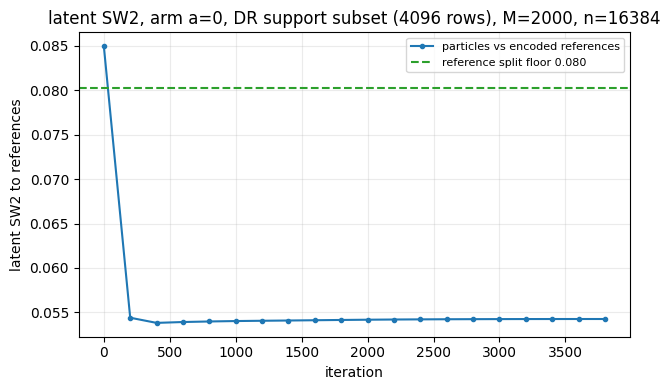

In [5]:
arm_indices = torch.nonzero(arm).ravel()
M = min(2000, len(arm_indices))       # the evaluation protocol's count (Dance et al.)
pick = arm_indices[torch.randperm(len(arm_indices),
                                  generator=torch.Generator().manual_seed(SEED))[:M]]
initial_particles = Z_std[pick].clone()
print(f"M = {M} particles (arm size {len(arm_indices)}); target support {len(dr_index)} rows")

torch.manual_seed(1)
flow_particles, history = adamw_riesz_flow(
    initial_particles.clone(), Z_target, target_weights=v_dr, sliced=False,
    n_iterations=4000, learning_rate=0.001, warmup_steps=100,
    lr_schedule="cosine", snapshot_every=200, verbose=True)
transport = (flow_particles - initial_particles).norm(dim=1).mean().item()
print(f"loss {history['loss'][0]:.4f} -> {history['loss'][-1]:.4f}   "
      f"mean transport {transport:.2f}")

snap_iters = sorted(history["snapshots"])
snap_sw2 = [sliced_wasserstein(history["snapshots"][it], Z_ref_std, p=2, seed=0).item()
            for it in snap_iters]
latent_floor = sliced_wasserstein(Z_ref_std[:1000], Z_ref_std[1000:], p=2, seed=0).item()
latent_sw2_initial = sliced_wasserstein(initial_particles, Z_ref_std, p=2, seed=0).item()
latent_sw2_flow = sliced_wasserstein(flow_particles, Z_ref_std, p=2, seed=0).item()
plt.figure(figsize=(6.5, 4))
plt.plot(snap_iters, snap_sw2, marker="o", ms=3, label="particles vs encoded references")
plt.axhline(latent_floor, ls="--", c="tab:green",
            label=f"reference split floor {latent_floor:.3f}")
plt.xlabel("iteration")
plt.ylabel("latent SW2 to references")
plt.title(f"latent SW2, arm a={TARGET_A}, DR support {DR_SUPPORT} "
          f"({len(dr_index)} rows), M={M}, n={n}")
plt.legend(fontsize=8)
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


## 5. Sampled Faces vs. Starting Faces

Top: decoded starting particles (observed arm). Middle: the decoded flowed particles, the
sampler's draw from the interventional law. Bottom: held-out reference samples, genuine draws
from $P(Y(a^\*))$. The flow is a distributional sampler with no per-image anchor, so
individual identities may change while the population is rebalanced.


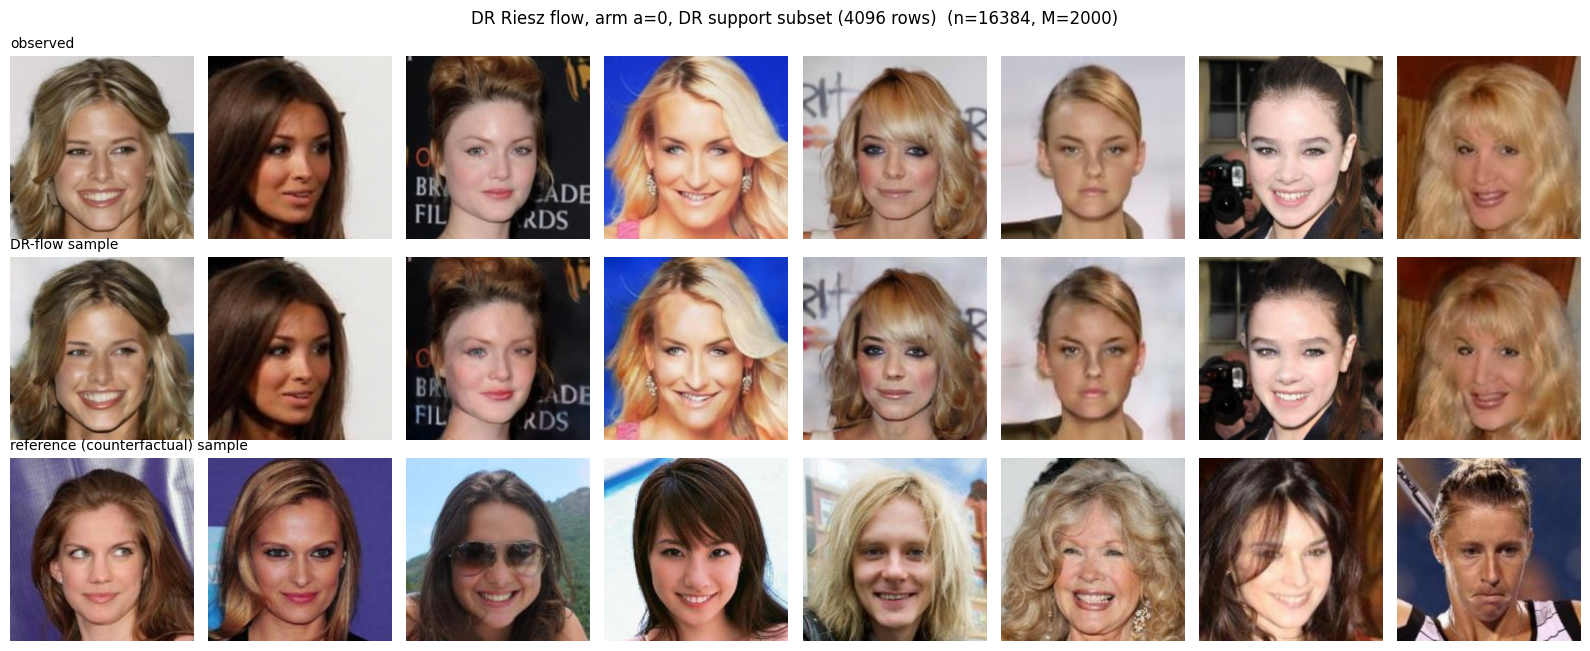

In [6]:
idx, n_show = 24, 8
ref_pick = torch.randperm(len(Y_ref), generator=torch.Generator().manual_seed(2))[:n_show]
with torch.no_grad():
    start_faces = decode_latents(vae, from_flow(initial_particles[idx:idx + n_show]), 256)
    flowed_faces = decode_latents(vae, from_flow(flow_particles[idx:idx + n_show]), 256)
reference_faces = Y_ref[ref_pick]
fig, axes = plt.subplots(3, n_show, figsize=(2.0 * n_show, 6.6))
for column in range(n_show):
    axes[0, column].imshow(to_image_range(start_faces[column]).permute(1, 2, 0).numpy())
    axes[1, column].imshow(to_image_range(flowed_faces[column]).permute(1, 2, 0).numpy())
    axes[2, column].imshow(to_image_range(reference_faces[column]).permute(1, 2, 0).numpy())
    for row in (0, 1, 2):
        axes[row, column].axis("off")
axes[0, 0].set_title("observed", fontsize=10, loc="left")
axes[1, 0].set_title("DR-flow sample", fontsize=10, loc="left")
axes[2, 0].set_title("reference (counterfactual) sample", fontsize=10, loc="left")
fig.suptitle(f"DR Riesz flow, arm a={TARGET_A}, DR support {DR_SUPPORT} "
             f"({len(dr_index)} rows)  (n={n}, M={M})", fontsize=12)
fig.tight_layout()
plt.show()


## 6. Structural Edits Along the Flow

Each row is one particle, each column a snapshot iteration. The particles shown are those
whose decoded image moves furthest over the run, so the edit is visible: the flow should
change hair colour and leave identity, pose and background alone. Degradation of identity or
background here, rather than a change of hair colour, is what a coarse target support looks
like.


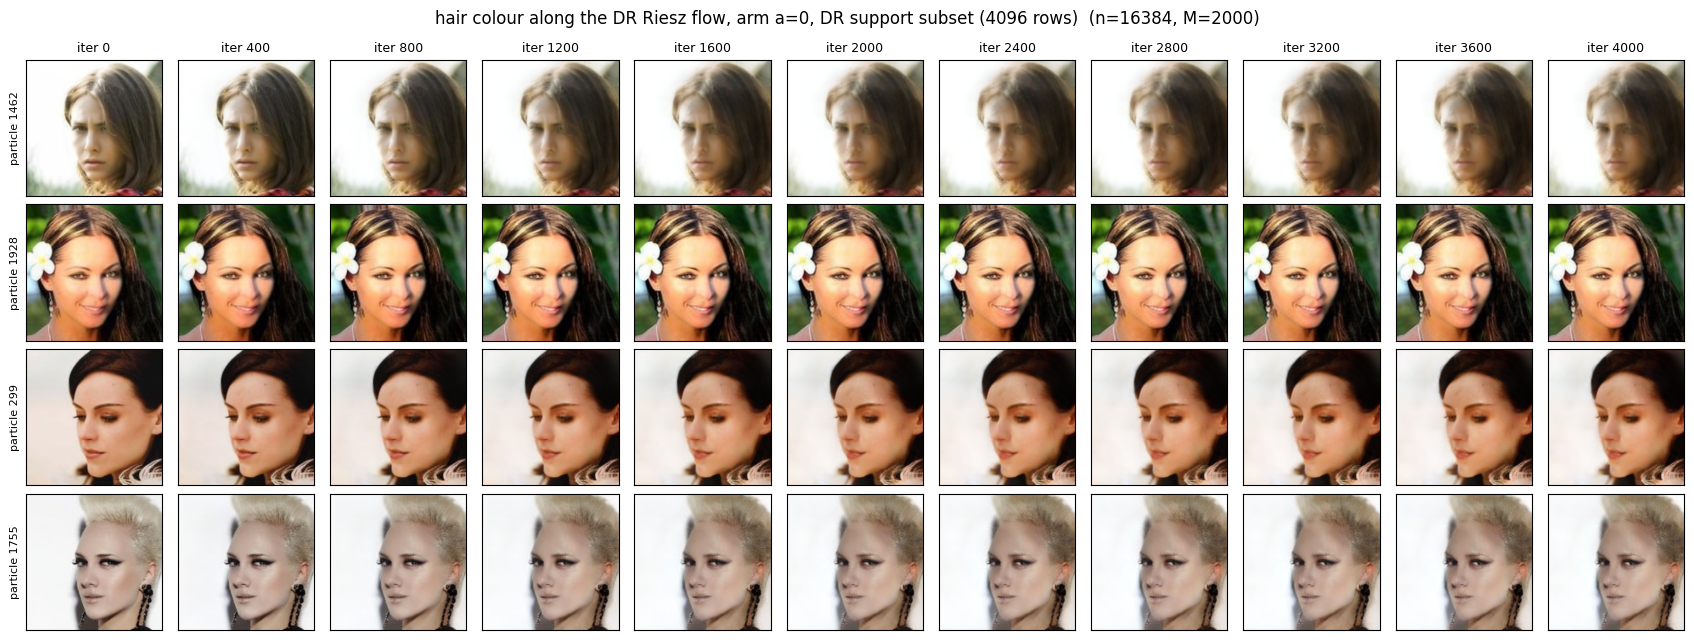

In [7]:
snapshot_iters = [it for it in sorted(history["snapshots"]) if it % 400 == 0]
if snapshot_iters[-1] != 4000:
    snapshot_iters.append(4000)
    history["snapshots"][4000] = flow_particles

moved = (flow_particles - initial_particles).norm(dim=1)
track = torch.topk(moved, 4).indices.tolist()
with torch.no_grad():
    frames = {it: decode_latents(vae, from_flow(history["snapshots"][it][track]), 256)
              for it in snapshot_iters}

fig, axes = plt.subplots(len(track), len(snapshot_iters),
                         figsize=(1.55 * len(snapshot_iters), 1.62 * len(track)))
for row, particle in enumerate(track):
    for column, it in enumerate(snapshot_iters):
        axes[row, column].imshow(to_image_range(frames[it][row]).permute(1, 2, 0).numpy())
        axes[row, column].set_xticks([]); axes[row, column].set_yticks([])
        if row == 0:
            axes[row, column].set_title(f"iter {it}", fontsize=9)
    axes[row, 0].set_ylabel(f"particle {particle}", fontsize=8)
fig.suptitle(f"hair colour along the DR Riesz flow, arm a={TARGET_A}, "
             f"DR support {DR_SUPPORT} ({len(dr_index)} rows)  (n={n}, M={M})", fontsize=12)
fig.tight_layout()
plt.show()


## 7. Metric Evaluation

The evaluation follows the protocol of Dance et al. (2026, App. B.3): the sample is scored
against $n_{\mathrm{ref}} = 2000$ held-out reference images of $P(Y(0))$ by sliced
Wasserstein-2 distance in flattened pixel space (1000 random projections, truncation to the
smaller sample). The table adds SW1 and unbiased squared MMD (median-heuristic RBF), plus two
diagnostic rows: the VAE round-trip of the observed arm, which isolates the decoder so that
any improvement beyond it is transport rather than smoothing, and a 1000/1000 split of the
references, the finite-sample floor.

The $64 \times 64$ block re-scores the same samples at the resolution of the paper's
Figure 4. FID is reported in both the legacy and the Clean variant and is never mixed across
variants in one comparison. **SW2 measures the intervention, FID measures validity; a run
that lowers SW2 below the reference floor while raising FID has over-transported, not
improved.** The final cell writes every number to a JSON file so the two notebooks of a pair
can be compared without re-running either.


In [8]:
with torch.no_grad():
    flow_images = decode_latents(vae, from_flow(flow_particles), 256)
observed_images = Y[arm_indices[:2000]]
flatten = lambda images: images.reshape(images.shape[0], -1)
kernel_pixel = RBF(use_length_scale_heuristic=True)
_ = kernel_pixel(flatten(Y_ref))
results = {"n_obs": int(n), "dr_support": DR_SUPPORT, "n_dr": int(len(dr_index)),
           "n_particles": int(M), "arm_size": int(len(arm_indices)),
           "target_a": int(TARGET_A), "transport": float(transport),
           "latent_sw2": {"initial": latent_sw2_initial, "flow": latent_sw2_flow,
                          "floor": latent_floor}}


def evaluate(images):
    reference = flatten(Y_ref)
    sw2 = sliced_wasserstein(flatten(images), reference, p=2, seed=0).item()
    sw1 = sliced_wasserstein(flatten(images), reference, p=1, seed=0).item()
    mmd2 = squared_mmd(kernel_pixel, flatten(images), reference, unbiased=True).item()
    return sw2, sw1, mmd2


with torch.no_grad():
    roundtrip_images = decode_latents(vae, encode_images(vae, observed_images), 256)
rows = {f"observed arm {TARGET_A} (base)": observed_images,
        "observed arm, VAE round-trip": roundtrip_images,
        "DR Riesz flow (target)": flow_images}
print(f"{'sample':30s} {'SW2':>8s} {'SW1':>8s} {'MMD^2':>10s}")
results["pixel_256"] = {}
for name, images in rows.items():
    sw2, sw1, mmd2 = evaluate(images)
    results["pixel_256"][name] = {"sw2": sw2, "sw1": sw1, "mmd2": mmd2}
    print(f"{name:30s} {sw2:8.4f} {sw1:8.4f} {mmd2:10.2e}")
sw2_f = sliced_wasserstein(flatten(Y_ref[:1000]), flatten(Y_ref[1000:]), p=2, seed=0).item()
sw1_f = sliced_wasserstein(flatten(Y_ref[:1000]), flatten(Y_ref[1000:]), p=1, seed=0).item()
mmd2_f = squared_mmd(kernel_pixel, flatten(Y_ref[:1000]), flatten(Y_ref[1000:]),
                     unbiased=True).item()
results["pixel_256"]["reference floor"] = {"sw2": sw2_f, "sw1": sw1_f, "mmd2": mmd2_f}
print(f"{'reference 1000/1000 floor':30s} {sw2_f:8.4f} {sw1_f:8.4f} {mmd2_f:10.2e}")

to_64 = lambda images: F.interpolate(images, size=64, mode="area").clamp(-1.0, 1.0)
ref_64 = flatten(to_64(Y_ref))
print()
print("64 x 64 evaluation (resolution of Dance et al., 2026, Figure 4):")
print(f"{'sample':30s} {'SW2':>8s} {'SW1':>8s}")
results["pixel_64"] = {}
for name, images in rows.items():
    sw2 = sliced_wasserstein(flatten(to_64(images)), ref_64, p=2, seed=0).item()
    sw1 = sliced_wasserstein(flatten(to_64(images)), ref_64, p=1, seed=0).item()
    results["pixel_64"][name] = {"sw2": sw2, "sw1": sw1}
    print(f"{name:30s} {sw2:8.4f} {sw1:8.4f}")
sw2_f64 = sliced_wasserstein(flatten(to_64(Y_ref[:1000])), flatten(to_64(Y_ref[1000:])),
                             p=2, seed=0).item()
sw1_f64 = sliced_wasserstein(flatten(to_64(Y_ref[:1000])), flatten(to_64(Y_ref[1000:])),
                             p=1, seed=0).item()
results["pixel_64"]["reference floor"] = {"sw2": sw2_f64, "sw1": sw1_f64}
print(f"{'reference 1000/1000 floor':30s} {sw2_f64:8.4f} {sw1_f64:8.4f}")

scorers = {"legacy": LegacyFIDScorer(device=device, batch_size=32),
           "clean": CleanFIDScorer(device=device, batch_size=32, num_workers=8,
                                   allow_download=False)}
print()
print("FID at 256 px (every row vs the 2000 RAW references; the round-trip row is the")
print("decoder ceiling -- what a perfect latent-space sampler could reach through this VAE):")
print(f"{'sample':30s} {'legacy':>9s} {'clean':>9s}")
results["fid_256"] = {}
reference_features = {key: scorer.features(Y_ref) for key, scorer in scorers.items()}
for name, images in rows.items():
    scores = {key: scorer.distance_from_features(scorer.features(images),
                                                 reference_features[key])
              for key, scorer in scorers.items()}
    results["fid_256"][name] = scores
    print(f"{name:30s} {scores['legacy']:9.2f} {scores['clean']:9.2f}")
floor_scores = {key: s.distance_from_features(s.features(Y_ref[:1000]),
                                              s.features(Y_ref[1000:]))
                for key, s in scorers.items()}
results["fid_256"]["reference floor"] = floor_scores
print(f"{'reference 1000/1000 floor':30s} {floor_scores['legacy']:9.2f} "
      f"{floor_scores['clean']:9.2f}")
print("(counts differ between rows: the floor is 1000 vs 1000, the others 2000 vs 2000;")
print(" FID is biased upward at smaller counts, so compare rows at equal counts only)")

out = f"results/celeba_female_dr_{DR_SUPPORT}_n{n}.json"
import os
os.makedirs("results", exist_ok=True)
with open(out, "w") as handle:
    json.dump(results, handle, indent=2)
print(f"\nwrote {out}")


sample                              SW2      SW1      MMD^2


observed arm 0 (base)            0.0494   0.0378   2.32e-03


observed arm, VAE round-trip     0.0494   0.0378   2.32e-03


DR Riesz flow (target)           0.0308   0.0216   1.30e-04


reference 1000/1000 floor        0.0445   0.0324   3.71e-04



64 x 64 evaluation (resolution of Dance et al., 2026, Figure 4):
sample                              SW2      SW1


... (5 outputs left out)

observed arm 0 (base)              10.23     12.36


observed arm, VAE round-trip       10.63     13.02


DR Riesz flow (target)             12.74     17.08


reference 1000/1000 floor          17.65     21.87
(counts differ between rows: the floor is 1000 vs 1000, the others 2000 vs 2000;
 FID is biased upward at smaller counts, so compare rows at equal counts only)

wrote results/celeba_female_dr_subset_n16384.json


## Summary

DR support: **4096 of 16384 logged rows**, the pre-2026-09 configuration, solved exactly.
Compare with `CelebA_Female_DR_FullSupport_n16384.ipynb`, which is identical except that its
support is every logged row.

- The cap binds here, and it damages the target twice over. The weights no longer reproduce
  the interventional marginal exactly, $\sum_i v_i X_i = 0.308$ against the full-support run's
  $0.300$, and the embedding is carried by a quarter as many atoms.
- Mean transport rises to $13.39$ from the full-support run's $8.47$. A target supported on
  fewer atoms behaves like a coarse quantisation of the interventional law, and particles
  travel further to reach it.
- Pixel SW2 reaches $0.0308$ at 256 px against the full-support run's $0.0271$; both are below
  the $0.0445$ reference floor, so SW2 alone understates the gap. It measures the intervention,
  not the validity of the images.
- FID exposes the cost. Legacy FID ends at $12.74$ against $10.67$ with the full support, and
  clean FID at $17.08$ against $13.38$. The VAE round-trip ceiling is $10.63$ legacy, so the
  full-support run reaches what a perfect latent sampler could through this decoder while this
  run ends well above it.
- This is the failure the current code was written to remove: capping the DR support to make
  each fold's ridge solve affordable trades image validity for tractability. The Nystrom solve
  of the sibling notebook buys the same tractability with the support left whole.
